# Detecção de Imagens Sintéticas — versão robusta

**Diferença para o `main.ipynb`:** o SVM treina com **original + todas as transformações** (mesmo rótulo). O notebook original (baseline 92%) permanece intacto.

**Fluxo:** carregar dados → definir transformações → extrair features (treino aumentado) → SVM RBF → medir acurácia no teste original e no teste transformado.

> Desenvolvedores: Igor de Matos da Rosa e Nathália Geraldino Ribas


## 1. Setup e caminhos
Preparar o ambiente e apontar para o CIFAKE.


In [1]:
# Importa bibliotecas do pipeline (mesmo conjunto do main.ipynb)
import hashlib
import os
import random
import time
from collections import Counter
from pathlib import Path

import atexit
import cv2
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from skimage.feature import hog, local_binary_pattern
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from tqdm import tqdm

def _fechar_figuras():
    plt.close("all")

atexit.register(_fechar_figuras)


<function __main__._fechar_figuras()>

In [2]:
# Caminhos: CIFAKE + pastas de saída (não sobrescreve os .pkl do baseline)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

HERE = Path.cwd()
try:
    HERE_NB = Path(__vsc_ipynb_file__).resolve().parent
except NameError:
    HERE_NB = HERE

if (HERE / "main_robusto.ipynb").exists() or (HERE / "main.ipynb").exists():
    ROOT_DIR = HERE
elif (HERE / "Cod" / "main_robusto.ipynb").exists():
    ROOT_DIR = HERE / "Cod"
elif (HERE_NB / "main_robusto.ipynb").exists():
    ROOT_DIR = HERE_NB
else:
    ROOT_DIR = HERE

possible_dataset_paths = [
    ROOT_DIR / "Base" / "archive",
    ROOT_DIR.parent / "Base" / "archive",
    ROOT_DIR / "archive",
]
DATASET_DIR = next((p for p in possible_dataset_paths if p.exists()), None)
if DATASET_DIR is None:
    raise FileNotFoundError("Pasta Base/archive (CIFAKE) não encontrada.")

TRAIN_DIR = DATASET_DIR / "train"
TEST_DIR = DATASET_DIR / "test"
MODELS_DIR = ROOT_DIR / "models"
RESULTS_DIR = ROOT_DIR / "results"
LOCAL_DIR = ROOT_DIR / "local"
for pasta in (MODELS_DIR, RESULTS_DIR, LOCAL_DIR):
    pasta.mkdir(parents=True, exist_ok=True)

print(f"Pasta do notebook: {ROOT_DIR}")
print(f"Dataset: {DATASET_DIR}")
print(f"Treino existe? {TRAIN_DIR.exists()} | Teste existe? {TEST_DIR.exists()}")


Pasta do notebook: /home/konath/Documentos/VC/DeteccaoImagensSinteticas/Cod
Dataset: /home/konath/Documentos/VC/DeteccaoImagensSinteticas/Base/archive
Treino existe? True | Teste existe? True


## 2. Carregar o CIFAKE
Dataset balanceado REAL/FAKE, já separado em treino e teste.


In [3]:
# Lista imagens REAL/FAKE e monta subconjunto balanceado
def listar_imagens(pasta_base):
    caminhos, rotulos = [], []
    classes = {"FAKE": 0, "REAL": 1}
    extensoes = {".jpg", ".jpeg", ".png"}
    for classe, rotulo in classes.items():
        pasta_classe = Path(pasta_base) / classe
        for imagem in pasta_classe.iterdir():
            if imagem.suffix.lower() in extensoes:
                caminhos.append(str(imagem))
                rotulos.append(rotulo)
    return caminhos, rotulos


def criar_subconjunto(caminhos, rotulos, quantidade_por_classe=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    fake_idx = [i for i, r in enumerate(rotulos) if r == 0]
    real_idx = [i for i, r in enumerate(rotulos) if r == 1]
    n_fake = min(quantidade_por_classe, len(fake_idx))
    n_real = min(quantidade_por_classe, len(real_idx))
    escolhidos = list(rng.choice(fake_idx, size=n_fake, replace=False))
    escolhidos += list(rng.choice(real_idx, size=n_real, replace=False))
    rng.shuffle(escolhidos)
    return [caminhos[i] for i in escolhidos], [rotulos[i] for i in escolhidos]


train_caminhos, train_rotulos = listar_imagens(TRAIN_DIR)
test_caminhos, test_rotulos = listar_imagens(TEST_DIR)
print("Train (completo):", Counter(train_rotulos))
print("Test (completo):", Counter(test_rotulos))


Train (completo): Counter({0: 50000, 1: 50000})
Test (completo): Counter({0: 10000, 1: 10000})


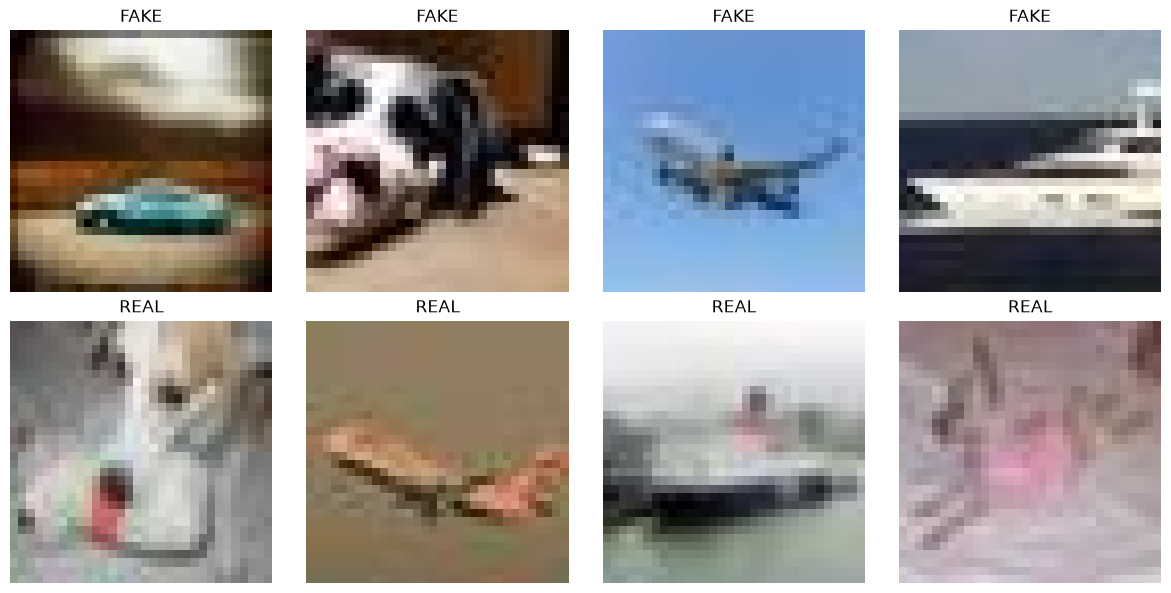

In [4]:
# Carrega RGB 32×32 (tamanho nativo do CIFAKE)
def carregar_imagem(caminho):
    imagem = cv2.imread(str(caminho))
    if imagem is None:
        raise ValueError(f"Não foi possível carregar: {caminho}")
    imagem = cv2.cvtColor(imagem, cv2.COLOR_BGR2RGB)
    if imagem.shape[0] != 32 or imagem.shape[1] != 32:
        imagem = cv2.resize(imagem, (32, 32), interpolation=cv2.INTER_AREA)
    return imagem


def mostrar_exemplos(caminhos, rotulos, quantidade=4):
    fake, real = [], []
    for caminho, rotulo in zip(caminhos, rotulos):
        if rotulo == 0 and len(fake) < quantidade:
            fake.append(caminho)
        elif rotulo == 1 and len(real) < quantidade:
            real.append(caminho)
        if len(fake) == quantidade and len(real) == quantidade:
            break
    exemplos = fake + real
    plt.figure(figsize=(12, 6))
    for i, caminho in enumerate(exemplos):
        plt.subplot(2, quantidade, i + 1)
        plt.imshow(carregar_imagem(caminho))
        plt.axis("off")
        plt.title("FAKE" if i < quantidade else "REAL")
    plt.tight_layout()
    plt.show()


mostrar_exemplos(train_caminhos, train_rotulos)


## 3. Extratores de features
Três famílias: **frequência (FFT)**, **espaço (HOG)**, **textura (LBP)**.


In [5]:
# FFT: espectro 2D → média radial (64 bins) normalizada em [0, 1]
def extrair_features_fft(imagem, num_bins=64):
    if len(imagem.shape) == 3:
        imagem_cinza = cv2.cvtColor(imagem, cv2.COLOR_RGB2GRAY)
    else:
        imagem_cinza = imagem.copy()
    fft_shifted = np.fft.fftshift(np.fft.fft2(imagem_cinza))
    magnitude_spectrum = np.log(np.abs(fft_shifted) + 1e-8)
    h, w = magnitude_spectrum.shape
    centro_y, centro_x = h // 2, w // 2
    y, x = np.ogrid[:h, :w]
    raios = np.sqrt((x - centro_x) ** 2 + (y - centro_y) ** 2)
    raio_max = np.sqrt(centro_x**2 + centro_y**2)
    bins = np.linspace(0, raio_max, num_bins + 1)
    vetor_fft = np.zeros(num_bins)
    for i in range(num_bins):
        mascara = (raios >= bins[i]) & (raios < bins[i + 1])
        if np.any(mascara):
            vetor_fft[i] = np.mean(magnitude_spectrum[mascara])
    min_val, max_val = np.min(vetor_fft), np.max(vetor_fft)
    if max_val - min_val > 1e-8:
        vetor_fft = (vetor_fft - min_val) / (max_val - min_val)
    return vetor_fft


img_teste = carregar_imagem(train_caminhos[0])
print("FFT shape:", extrair_features_fft(img_teste).shape)


FFT shape: (64,)


In [6]:
# HOG 32×32: células 8×8, blocos 2×2, 8 orientações
def extrair_features_hog(
    imagem, orientations=8, pixels_per_cell=(8, 8), cells_per_block=(2, 2)
):
    if len(imagem.shape) == 3:
        imagem_cinza = cv2.cvtColor(imagem, cv2.COLOR_RGB2GRAY)
    else:
        imagem_cinza = imagem.copy()
    return hog(
        imagem_cinza,
        orientations=orientations,
        pixels_per_cell=pixels_per_cell,
        cells_per_block=cells_per_block,
        block_norm="L2-Hys",
        visualize=False,
    )


print("HOG shape:", extrair_features_hog(img_teste).shape)


HOG shape: (288,)


In [7]:
# LBP uniforme P=8, R=1 → histograma de 10 bins
def extrair_features_lbp(imagem, P=8, R=1, method="uniform"):
    if len(imagem.shape) == 3:
        imagem_cinza = cv2.cvtColor(imagem, cv2.COLOR_RGB2GRAY)
    else:
        imagem_cinza = imagem.copy()
    lbp_mapa = local_binary_pattern(imagem_cinza, P=P, R=R, method=method)
    n_bins = P + 2 if method == "uniform" else int(lbp_mapa.max() + 1)
    hist, _ = np.histogram(lbp_mapa.ravel(), bins=n_bins, range=(0, n_bins))
    hist = hist.astype("float")
    soma = hist.sum()
    if soma > 0:
        hist /= soma
    return hist


print("LBP shape:", extrair_features_lbp(img_teste).shape)


LBP shape: (10,)


In [8]:
# Extrai features de uma lista de caminhos (teste original) com cache .npz
EXTRATORES = {
    "fft": extrair_features_fft,
    "hog": extrair_features_hog,
    "lbp": extrair_features_lbp,
}


def carregar_npz(caminho):
    """Lê .npz; None se o arquivo não existe ou está corrompido."""
    caminho = Path(caminho)
    if not caminho.exists():
        return None
    try:
        return np.load(caminho)
    except Exception as e:
        print(f"Cache ilegível ({caminho.name}): {e} — recalculando")
        try:
            caminho.unlink()
        except OSError:
            pass
        return None


def extrair_e_salvar_features(
    caminhos, rotulos, tipo_feature, pasta_saida="./local", nome_arquivo=None, forcar_recalculo=False
):
    if tipo_feature not in EXTRATORES:
        raise ValueError(f"Feature inválida: {tipo_feature}")
    diretorio_saida = Path(pasta_saida)
    diretorio_saida.mkdir(parents=True, exist_ok=True)
    if nome_arquivo is None:
        nome_arquivo = f"features_{tipo_feature}.npz"
    caminho_salvar = diretorio_saida / nome_arquivo
    if not forcar_recalculo:
        dados = carregar_npz(caminho_salvar)
        if dados is not None:
            print(f"Cache: {caminho_salvar.name} | X={dados['X'].shape}")
            return dados["X"], dados["y"]
    funcao = EXTRATORES[tipo_feature]
    vetores = [funcao(carregar_imagem(c)) for c in tqdm(caminhos, desc=tipo_feature)]
    X, y = np.array(vetores), np.array(rotulos)
    np.savez_compressed(caminho_salvar, X=X, y=y)
    print(f"Salvo: {caminho_salvar.name} | X={X.shape}")
    return X, y


## 4. Transformações digitais
Mesmo catálogo do `main.ipynb`. Aqui elas entram **no treino** (e depois no teste).


In [9]:
# JPEG em memória — devolve RGB 32×32
def jpeg_compress(imagem, qualidade=70):
    bgr = cv2.cvtColor(imagem, cv2.COLOR_RGB2BGR)
    ok, buffer = cv2.imencode(".jpg", bgr, [int(cv2.IMWRITE_JPEG_QUALITY), int(qualidade)])
    if not ok:
        raise RuntimeError("Falha ao comprimir JPEG.")
    return cv2.cvtColor(cv2.imdecode(buffer, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)


def crop_aleatorio(imagem, percentual=0.25, seed=None):
    if not 0 < percentual < 1:
        raise ValueError("percentual deve estar entre 0 e 1.")
    h, w = imagem.shape[:2]
    novo_h = max(1, int(h * (1 - percentual)))
    novo_w = max(1, int(w * (1 - percentual)))
    rng = np.random.default_rng(seed)
    y0 = int(rng.integers(0, h - novo_h + 1))
    x0 = int(rng.integers(0, w - novo_w + 1))
    recorte = imagem[y0 : y0 + novo_h, x0 : x0 + novo_w]
    return cv2.resize(recorte, (w, h), interpolation=cv2.INTER_LINEAR)


def resize_down_up(imagem, escala=0.5):
    if not 0 < escala < 1:
        raise ValueError("escala deve estar entre 0 e 1.")
    h, w = imagem.shape[:2]
    reduzida = cv2.resize(
        imagem, (max(1, int(w * escala)), max(1, int(h * escala))), interpolation=cv2.INTER_AREA
    )
    return cv2.resize(reduzida, (w, h), interpolation=cv2.INTER_LINEAR)


def blur(imagem, ksize=3):
    k = int(ksize)
    if k % 2 == 0:
        k += 1
    return cv2.GaussianBlur(imagem, (k, k), 0)


def pipeline_compartilhamento(imagem, seed=SEED):
    img = crop_aleatorio(imagem, percentual=0.25, seed=seed)
    img = resize_down_up(img, escala=0.5)
    return jpeg_compress(img, qualidade=70)


In [10]:
# Catálogo: no teste seed=SEED (igual à v1, reaproveita cache); no treino passa seed por imagem
TRANSFORMACOES = {
    "jpeg_90": lambda img, seed=None: jpeg_compress(img, 90),
    "jpeg_70": lambda img, seed=None: jpeg_compress(img, 70),
    "jpeg_50": lambda img, seed=None: jpeg_compress(img, 50),
    "crop_10": lambda img, seed=None: crop_aleatorio(img, 0.10, seed=SEED if seed is None else seed),
    "crop_25": lambda img, seed=None: crop_aleatorio(img, 0.25, seed=SEED if seed is None else seed),
    "crop_40": lambda img, seed=None: crop_aleatorio(img, 0.40, seed=SEED if seed is None else seed),
    "resize_0.5": lambda img, seed=None: resize_down_up(img, 0.5),
    "blur_3": lambda img, seed=None: blur(img, 3),
    "pipeline": lambda img, seed=None: pipeline_compartilhamento(
        img, seed=SEED if seed is None else seed
    ),
}
VARIANTES_TREINO = ["original"] + list(TRANSFORMACOES.keys())


def seed_variante(caminho, nome):
    """Seed estável entre execuções (hash() do Python muda a cada processo)."""
    chave = f"{caminho}|{nome}|{SEED}".encode()
    return int(hashlib.md5(chave).hexdigest()[:8], 16) % (2**31 - 1)


def aplicar_variante(imagem, nome, seed=None):
    if nome == "original":
        return imagem
    return TRANSFORMACOES[nome](imagem, seed=seed)


img_demo = carregar_imagem(train_caminhos[0])
print("Variantes de treino:", VARIANTES_TREINO)
for nome in TRANSFORMACOES:
    out = TRANSFORMACOES[nome](img_demo)
    assert out.shape[:2] == (32, 32), (nome, out.shape)
    assert out.dtype == np.uint8, (nome, out.dtype)
    print(f"  {nome:12s} {out.shape} {out.dtype}")


Variantes de treino: ['original', 'jpeg_90', 'jpeg_70', 'jpeg_50', 'crop_10', 'crop_25', 'crop_40', 'resize_0.5', 'blur_3', 'pipeline']
  jpeg_90      (32, 32, 3) uint8
  jpeg_70      (32, 32, 3) uint8
  jpeg_50      (32, 32, 3) uint8
  crop_10      (32, 32, 3) uint8
  crop_25      (32, 32, 3) uint8
  crop_40      (32, 32, 3) uint8
  resize_0.5   (32, 32, 3) uint8
  blur_3       (32, 32, 3) uint8
  pipeline     (32, 32, 3) uint8


## 5. Features de treino aumentado + teste original

**Decisão:** cada imagem de treino vira 10 amostras (original + 9 transformações), mesmo rótulo.

**Decisão:** `MODO=completo` usa 5000/classe × 10 = **100 mil** amostras — mesma ordem de grandeza do SVM da v1, viável à noite. O teste continua com o CIFAKE completo (20 mil).


In [11]:
# Escala: completo = noite (~100k amostras aumentadas, teste 20k)
MODO = "completo"
CONFIG_SUBSET = {
    "rapido": {"treino": 400, "teste": 300},
    "medio": {"treino": 1000, "teste": 500},
    "forte": {"treino": 3000, "teste": 1000},
    "completo": {"treino": 5000, "teste": None},
}
if MODO not in CONFIG_SUBSET:
    raise ValueError(f"MODO inválido: {MODO}")

N_TREINO_POR_CLASSE = CONFIG_SUBSET[MODO]["treino"]
N_TESTE_POR_CLASSE = CONFIG_SUBSET[MODO]["teste"]

train_caminhos_usados, train_rotulos_usados = criar_subconjunto(
    train_caminhos, train_rotulos, quantidade_por_classe=N_TREINO_POR_CLASSE
)
if N_TESTE_POR_CLASSE is None:
    test_caminhos_usados, test_rotulos_usados = test_caminhos, test_rotulos
else:
    test_caminhos_usados, test_rotulos_usados = criar_subconjunto(
        test_caminhos, test_rotulos, quantidade_por_classe=N_TESTE_POR_CLASSE
    )

n_imgs = len(train_caminhos_usados)
n_var = len(VARIANTES_TREINO)
print(f"MODO={MODO}")
print(f"Imagens-base treino: {n_imgs} {Counter(train_rotulos_usados)}")
print(f"Amostras após aumento: {n_imgs * n_var} ({n_var} variantes)")
print(f"Teste: {len(test_caminhos_usados)} {Counter(test_rotulos_usados)}")


MODO=completo
Imagens-base treino: 10000 Counter({0: 5000, 1: 5000})
Amostras após aumento: 100000 (10 variantes)
Teste: 20000 Counter({0: 10000, 1: 10000})


In [12]:
# Extrai original + todas as transformações; cache separado do baseline
def extrair_treino_aumentado(
    caminhos, rotulos, tipo_feature, pasta_saida="./local", forcar_recalculo=False
):
    if tipo_feature not in EXTRATORES:
        raise ValueError(f"Feature inválida: {tipo_feature}")
    Path(pasta_saida).mkdir(parents=True, exist_ok=True)
    n, n_var = len(caminhos), len(VARIANTES_TREINO)
    caminho = Path(pasta_saida) / f"features_{tipo_feature}_train_aug_n{n}_v{n_var}.npz"
    if not forcar_recalculo:
        dados = carregar_npz(caminho)
        if dados is not None:
            print(f"Cache aug: {caminho.name} | X={dados['X'].shape}")
            return dados["X"], dados["y"]

    funcao = EXTRATORES[tipo_feature]
    vetores, ys = [], []
    for caminho_img, y in tqdm(
        zip(caminhos, rotulos), total=n, desc=f"aug-{tipo_feature}"
    ):
        img = carregar_imagem(caminho_img)
        for nome in VARIANTES_TREINO:
            img_t = aplicar_variante(img, nome, seed=seed_variante(caminho_img, nome))
            vetores.append(funcao(img_t))
            ys.append(y)
    X, y_out = np.array(vetores), np.array(ys)
    np.savez_compressed(caminho, X=X, y=y_out)
    print(f"Salvo aug: {caminho.name} | X={X.shape}")
    return X, y_out


tipos_features = ["fft", "hog", "lbp"]
features, scalers = {}, {}
TAG_TESTE = len(test_caminhos_usados)

for tipo in tipos_features:
    print(f"\n=== {tipo.upper()} ===")
    X_train, y_train = extrair_treino_aumentado(
        train_caminhos_usados, train_rotulos_usados, tipo, pasta_saida=LOCAL_DIR
    )
    n_esperado = len(train_caminhos_usados) * len(VARIANTES_TREINO)
    assert X_train.shape[0] == n_esperado, (tipo, X_train.shape, n_esperado)
    X_test, y_test = extrair_e_salvar_features(
        test_caminhos_usados,
        test_rotulos_usados,
        tipo,
        pasta_saida=LOCAL_DIR,
        nome_arquivo=f"features_{tipo}_test_n{TAG_TESTE}.npz",
    )
    scaler = StandardScaler()
    features[tipo] = {
        "X_train": scaler.fit_transform(X_train),
        "y_train": y_train,
        "X_test": scaler.transform(X_test),
        "y_test": y_test,
    }
    scalers[tipo] = scaler
    assert np.isfinite(features[tipo]["X_train"]).all()
    assert np.isfinite(features[tipo]["X_test"]).all()
    print("Treino:", features[tipo]["X_train"].shape, "| Teste:", features[tipo]["X_test"].shape)

y_ref = features[tipos_features[0]]["y_train"]
y_test_ref = features[tipos_features[0]]["y_test"]
for tipo in tipos_features[1:]:
    assert features[tipo]["y_train"].shape == y_ref.shape
    assert np.array_equal(features[tipo]["y_train"], y_ref)
    assert np.array_equal(features[tipo]["y_test"], y_test_ref)

features["fusion"] = {
    "X_train": np.hstack([features[t]["X_train"] for t in tipos_features]),
    "y_train": y_ref,
    "X_test": np.hstack([features[t]["X_test"] for t in tipos_features]),
    "y_test": y_test_ref,
}
print("FUSION:", features["fusion"]["X_train"].shape, features["fusion"]["X_test"].shape)

for tipo in tipos_features:
    joblib.dump(scalers[tipo], MODELS_DIR / f"scaler_robusto_{tipo}.pkl")
print("Scalers salvos.")



=== FFT ===


aug-fft: 100%|██████████| 10000/10000 [01:31<00:00, 109.84it/s]


Salvo aug: features_fft_train_aug_n10000_v10.npz | X=(100000, 64)


fft: 100%|██████████| 20000/20000 [00:16<00:00, 1188.98it/s]


Salvo: features_fft_test_n20000.npz | X=(20000, 64)
Treino: (100000, 64) | Teste: (20000, 64)

=== HOG ===


aug-hog: 100%|██████████| 10000/10000 [00:31<00:00, 316.09it/s]


... (3 outputs left out)

aug-lbp: 100%|██████████| 10000/10000 [00:36<00:00, 276.32it/s]


Salvo aug: features_lbp_train_aug_n10000_v10.npz | X=(100000, 10)


lbp: 100%|██████████| 20000/20000 [00:06<00:00, 2933.37it/s]


Salvo: features_lbp_test_n20000.npz | X=(20000, 10)
Treino: (100000, 10) | Teste: (20000, 10)
FUSION: (100000, 362) (20000, 362)
Scalers salvos.


## 6. Treinar SVM RBF (modelo robusto)
Mesmo classificador da v1 (`SVC` kernel RBF, C=10), agora com `probability=True` (calibração Platt) para o app exibir chance real de ser IA.

Acurácia impressa aqui é no **teste original**. O cache de features da execução anterior é reaproveitado — só o treino do SVM roda de novo.

> Com probabilidade o treino fica mais longo (~2×). Com cache pronto, a noite cobre o retreino.


In [13]:
# SVM RBF — GridSearch de C só se n ≤ 20k
AJUSTAR_HIPERPARAMETROS = True


def criar_svm_rbf(C=10.0, gamma="scale"):
    # probability=True: calibra Platt e libera predict_proba (necessário no app)
    return SVC(
        kernel="rbf",
        C=C,
        gamma=gamma,
        probability=True,
        random_state=SEED,
        cache_size=2000,
    )


def treinar_e_avaliar(X_train, y_train, X_test, y_test, modelo):
    t0 = time.time()
    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)
    return modelo, accuracy_score(y_test, y_pred), y_pred, time.time() - t0


def treinar_svm_rbf_otimizado(X_train, y_train, X_test, y_test, nome):
    n = len(y_train)
    usar_grid = AJUSTAR_HIPERPARAMETROS and n <= 20000
    if usar_grid:
        print(f"  GridSearch C no RBF [{nome}] (n={n})...")
        gs = GridSearchCV(
            criar_svm_rbf(), param_grid={"C": [1.0, 10.0, 50.0]}, cv=3, n_jobs=-1, scoring="accuracy"
        )
        t0 = time.time()
        gs.fit(X_train, y_train)
        y_pred = gs.best_estimator_.predict(X_test)
        acc = accuracy_score(y_test, y_pred)
        print(f"  Melhor C={gs.best_params_['C']}")
        return gs.best_estimator_, acc, y_pred, time.time() - t0
    print(f"  Treino RBF fixo C=10 [{nome}] (n={n})...")
    return treinar_e_avaliar(X_train, y_train, X_test, y_test, criar_svm_rbf(C=10.0))


baseline_results, tabela_resumo = {}, []
for tipo in tipos_features:
    print(f"\n=== SVM RBF robusto [{tipo.upper()}] ===")
    modelo, acc, y_pred, dt = treinar_svm_rbf_otimizado(
        features[tipo]["X_train"],
        features[tipo]["y_train"],
        features[tipo]["X_test"],
        features[tipo]["y_test"],
        tipo.upper(),
    )
    baseline_results[tipo] = {"modelo": modelo, "acuracia": acc, "y_pred": y_pred}
    joblib.dump(modelo, MODELS_DIR / f"svm_robusto_{tipo}.pkl")
    tabela_resumo.append(
        {"feature": tipo.upper(), "modelo": "SVC-RBF-aug", "n_treino": len(features[tipo]["y_train"]),
         "acurácia_orig": f"{acc:.4f}", "tempo_s": f"{dt:.1f}"}
    )
    print(f"  → teste original acc={acc:.4f} | tempo={dt:.1f}s | salvo svm_robusto_{tipo}.pkl")

print("\n=== SVM RBF robusto [FUSION] ===")
modelo_f, acc_f, y_pred_f, dt_f = treinar_svm_rbf_otimizado(
    features["fusion"]["X_train"],
    features["fusion"]["y_train"],
    features["fusion"]["X_test"],
    features["fusion"]["y_test"],
    "FUSION",
)
baseline_results["fusion"] = {"modelo": modelo_f, "acuracia": acc_f, "y_pred": y_pred_f}
joblib.dump(modelo_f, MODELS_DIR / "svm_robusto_fusion.pkl")
tabela_resumo.append(
    {"feature": "FUSION", "modelo": "SVC-RBF-aug", "n_treino": len(features["fusion"]["y_train"]),
     "acurácia_orig": f"{acc_f:.4f}", "tempo_s": f"{dt_f:.1f}"}
)
print(f"  → FUSION teste original acc={acc_f:.4f} | tempo={dt_f:.1f}s | salvo svm_robusto_fusion.pkl")
df_baseline = pd.DataFrame(tabela_resumo)
print("\n" + df_baseline.to_string(index=False))

# Confirma que o app terá probabilidade calibrada
proba = baseline_results["fusion"]["modelo"].predict_proba(features["fusion"]["X_test"][:3])
print("\npredict_proba (3 amostras, colunas = classes do SVM):")
print(proba)
print("classes_:", baseline_results["fusion"]["modelo"].classes_)



=== SVM RBF robusto [FFT] ===
  Treino RBF fixo C=10 [FFT] (n=100000)...


/home/konath/.local/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


  → teste original acc=0.7531 | tempo=7354.7s | salvo svm_robusto_fft.pkl

=== SVM RBF robusto [HOG] ===
  Treino RBF fixo C=10 [HOG] (n=100000)...


/home/konath/.local/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


  → teste original acc=0.7632 | tempo=49215.3s | salvo svm_robusto_hog.pkl

=== SVM RBF robusto [LBP] ===
  Treino RBF fixo C=10 [LBP] (n=100000)...


/home/konath/.local/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


  → teste original acc=0.7126 | tempo=2736.9s | salvo svm_robusto_lbp.pkl

=== SVM RBF robusto [FUSION] ===
  Treino RBF fixo C=10 [FUSION] (n=100000)...


/home/konath/.local/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


  → FUSION teste original acc=0.8597 | tempo=43444.0s | salvo svm_robusto_fusion.pkl

feature      modelo  n_treino acurácia_orig tempo_s
    FFT SVC-RBF-aug    100000        0.7531  7354.7
    HOG SVC-RBF-aug    100000        0.7632 49215.3
    LBP SVC-RBF-aug    100000        0.7126  2736.9
 FUSION SVC-RBF-aug    100000        0.8597 43444.0

predict_proba (3 amostras, colunas = classes do SVM):
[[0.95263925 0.04736075]
 [0.93279084 0.06720916]
 [0.989771   0.010229  ]]
classes_: [0 1]


In [14]:
# Salva com prefixo robusto — não apaga svm_fusion.pkl da v1
for tipo in tipos_features:
    joblib.dump(baseline_results[tipo]["modelo"], MODELS_DIR / f"svm_robusto_{tipo}.pkl")
    joblib.dump(scalers[tipo], MODELS_DIR / f"scaler_robusto_{tipo}.pkl")
    print(f"Salvo svm_robusto_{tipo}.pkl + scaler_robusto_{tipo}.pkl")
joblib.dump(baseline_results["fusion"]["modelo"], MODELS_DIR / "svm_robusto_fusion.pkl")
print(f"Salvo svm_robusto_fusion.pkl (acc original={baseline_results['fusion']['acuracia']:.4f})")


Salvo svm_robusto_fft.pkl + scaler_robusto_fft.pkl
Salvo svm_robusto_hog.pkl + scaler_robusto_hog.pkl
Salvo svm_robusto_lbp.pkl + scaler_robusto_lbp.pkl
Salvo svm_robusto_fusion.pkl (acc original=0.8597)


## 7. Avaliação sob transformações
O classificador **não** é retreinado. Só o teste muda (iguais à v1).


In [15]:
# Features a partir de arrays já transformados + cache por (feature, transf, n)
def extrair_features_de_imagens(imagens, tipo_feature):
    funcao = EXTRATORES[tipo_feature]
    return np.array(
        [funcao(img) for img in tqdm(imagens, desc=f"Features {tipo_feature}", leave=False)]
    )


def caminho_cache_transf(pasta_saida, tipo_feature, nome_transformacao, n):
    return Path(pasta_saida) / f"features_{tipo_feature}_test_{nome_transformacao}_n{n}.npz"


def obter_features_por_transformacao(
    caminhos, rotulos, nome_transformacao, funcao_transformacao, tipos,
    pasta_saida="./local", forcar_recalculo=False,
):
    diretorio = Path(pasta_saida)
    diretorio.mkdir(parents=True, exist_ok=True)
    n, y = len(caminhos), np.array(rotulos)
    caches = {t: caminho_cache_transf(pasta_saida, t, nome_transformacao, n) for t in tipos}
    Xs, faltando = {}, []
    for tipo, caminho in caches.items():
        dados = None if forcar_recalculo else carregar_npz(caminho)
        if dados is not None:
            Xs[tipo] = dados["X"]
            print(f"  Cache: {caminho.name} | X={Xs[tipo].shape}")
        else:
            faltando.append(tipo)
    if faltando:
        imagens_transf = [
            funcao_transformacao(carregar_imagem(c))
            for c in tqdm(caminhos, desc=f"Aplicando {nome_transformacao}", leave=False)
        ]
        for tipo in faltando:
            X = extrair_features_de_imagens(imagens_transf, tipo)
            np.savez_compressed(caches[tipo], X=X, y=y)
            Xs[tipo] = X
            print(f"  Salvo: {caches[tipo].name} | X={X.shape}")
    return Xs, y


In [16]:
# Recupera modelos se o kernel caiu no meio da noite
def carregar_se_preciso():
    global baseline_results, scalers
    if "baseline_results" not in globals() or not baseline_results:
        baseline_results = {}
        for tipo in tipos_features:
            modelo = joblib.load(MODELS_DIR / f"svm_robusto_{tipo}.pkl")
            acc = float("nan")
            if "features" in globals() and tipo in features:
                acc = accuracy_score(
                    features[tipo]["y_test"], modelo.predict(features[tipo]["X_test"])
                )
            baseline_results[tipo] = {"modelo": modelo, "acuracia": acc}
    if "scalers" not in globals() or not scalers:
        scalers = {
            tipo: joblib.load(MODELS_DIR / f"scaler_robusto_{tipo}.pkl")
            for tipo in tipos_features
        }
    if "fusion" not in baseline_results:
        modelo_f = joblib.load(MODELS_DIR / "svm_robusto_fusion.pkl")
        acc_f = float("nan")
        if "features" in globals() and "fusion" in features:
            acc_f = accuracy_score(
                features["fusion"]["y_test"], modelo_f.predict(features["fusion"]["X_test"])
            )
        baseline_results["fusion"] = {"modelo": modelo_f, "acuracia": acc_f}


carregar_se_preciso()
print(
    f"Avaliar {len(TRANSFORMACOES)} transf. × 3 features + FUSION "
    f"em {len(test_caminhos_usados)} imagens."
)

resultados_robustez = []
for nome_transf, funcao_transf in TRANSFORMACOES.items():
    print(f"\n=== {nome_transf} ===")
    Xs_transf, y_transf = obter_features_por_transformacao(
        test_caminhos_usados,
        test_rotulos_usados,
        nome_transf,
        funcao_transf,
        tipos_features,
        pasta_saida=LOCAL_DIR,
    )
    X_scaled_por_tipo = {}
    for tipo in tipos_features:
        X_scaled = scalers[tipo].transform(Xs_transf[tipo])
        X_scaled_por_tipo[tipo] = X_scaled
        acc = accuracy_score(y_transf, baseline_results[tipo]["modelo"].predict(X_scaled))
        base = baseline_results[tipo]["acuracia"]
        resultados_robustez.append(
            {"transformacao": nome_transf, "feature": tipo.upper(),
             "acuracia": acc, "baseline": base, "queda": base - acc}
        )
        print(f"  {tipo.upper():3s} | acc={acc:.4f} | orig={base:.4f} | queda={base - acc:+.4f}")
    X_fusion = np.hstack([X_scaled_por_tipo[t] for t in tipos_features])
    acc_f = accuracy_score(y_transf, baseline_results["fusion"]["modelo"].predict(X_fusion))
    base_f = baseline_results["fusion"]["acuracia"]
    resultados_robustez.append(
        {"transformacao": nome_transf, "feature": "FUSION",
         "acuracia": acc_f, "baseline": base_f, "queda": base_f - acc_f}
    )
    print(f"  FUSION | acc={acc_f:.4f} | orig={base_f:.4f} | queda={base_f - acc_f:+.4f}")
print(f"\nTotal: {len(resultados_robustez)}")


Avaliar 9 transf. × 3 features + FUSION em 20000 imagens.

=== jpeg_90 ===


  Salvo: features_fft_test_jpeg_90_n20000.npz | X=(20000, 64)


  Salvo: features_hog_test_jpeg_90_n20000.npz | X=(20000, 288)


  Salvo: features_lbp_test_jpeg_90_n20000.npz | X=(20000, 10)
  FFT | acc=0.7550 | orig=0.7531 | queda=-0.0020
  HOG | acc=0.7645 | orig=0.7632 | queda=-0.0013
  LBP | acc=0.7085 | orig=0.7126 | queda=+0.0041
  FUSION | acc=0.8581 | orig=0.8597 | queda=+0.0016

=== jpeg_70 ===


  Salvo: features_fft_test_jpeg_70_n20000.npz | X=(20000, 64)


  Salvo: features_hog_test_jpeg_70_n20000.npz | X=(20000, 288)


... (18 outputs left out)

  Salvo: features_lbp_test_blur_3_n20000.npz | X=(20000, 10)
  FFT | acc=0.7058 | orig=0.7531 | queda=+0.0473
  HOG | acc=0.7389 | orig=0.7632 | queda=+0.0243
  LBP | acc=0.6657 | orig=0.7126 | queda=+0.0469
  FUSION | acc=0.8181 | orig=0.8597 | queda=+0.0416

=== pipeline ===


  Salvo: features_fft_test_pipeline_n20000.npz | X=(20000, 64)


  Salvo: features_hog_test_pipeline_n20000.npz | X=(20000, 288)


  Salvo: features_lbp_test_pipeline_n20000.npz | X=(20000, 10)
  FFT | acc=0.5882 | orig=0.7531 | queda=+0.1649
  HOG | acc=0.6538 | orig=0.7632 | queda=+0.1095
  LBP | acc=0.5999 | orig=0.7126 | queda=+0.1127
  FUSION | acc=0.7092 | orig=0.8597 | queda=+0.1505

Total: 36


In [17]:
# Tabela + CSV (não sobrescreve metrics.csv da v1)
df_robustez = pd.DataFrame(resultados_robustez).sort_values("queda", ascending=False).reset_index(drop=True)
df_exibir = df_robustez.copy()
for col in ["acuracia", "baseline", "queda"]:
    df_exibir[col] = df_exibir[col].map(lambda x: f"{x:.4f}")
caminho_csv = RESULTS_DIR / "metrics_robusto.csv"
df_robustez.to_csv(caminho_csv, index=False)
print(df_exibir.to_string(index=False))
print(f"\nCSV: {caminho_csv}")
print("\nPior queda por feature:")
for feat in [t.upper() for t in tipos_features] + ["FUSION"]:
    s = df_robustez[df_robustez["feature"] == feat].iloc[0]
    print(f"  {feat:6s} → {s['transformacao']} (queda={s['queda']:+.4f}, acc={s['acuracia']:.4f})")


transformacao feature acuracia baseline   queda
     pipeline     FFT   0.5882   0.7531  0.1649
      crop_10     FFT   0.6017   0.7531  0.1514
     pipeline  FUSION   0.7092   0.8597  0.1505
      crop_40  FUSION   0.7389   0.8597  0.1208
      crop_40     HOG   0.6427   0.7632  0.1206
     pipeline     LBP   0.5999   0.7126  0.1127
     pipeline     HOG   0.6538   0.7632  0.1095
   resize_0.5     FFT   0.6493   0.7531  0.1038
      crop_40     LBP   0.6172   0.7126  0.0954
      crop_40     FFT   0.6676   0.7531  0.0855
      crop_25     HOG   0.6804   0.7632  0.0828
      crop_25     LBP   0.6308   0.7126  0.0818
      crop_25  FUSION   0.7797   0.8597  0.0800
      crop_25     FFT   0.6761   0.7531  0.0770
   resize_0.5  FUSION   0.7881   0.8597  0.0716
      crop_10     LBP   0.6545   0.7126  0.0581
      crop_10  FUSION   0.8096   0.8597  0.0501
       blur_3     FFT   0.7058   0.7531  0.0473
       blur_3     LBP   0.6657   0.7126  0.0469
       blur_3  FUSION   0.8181   0.8597 

## 8. Gráficos
Barras e heatmap da versão robusta.


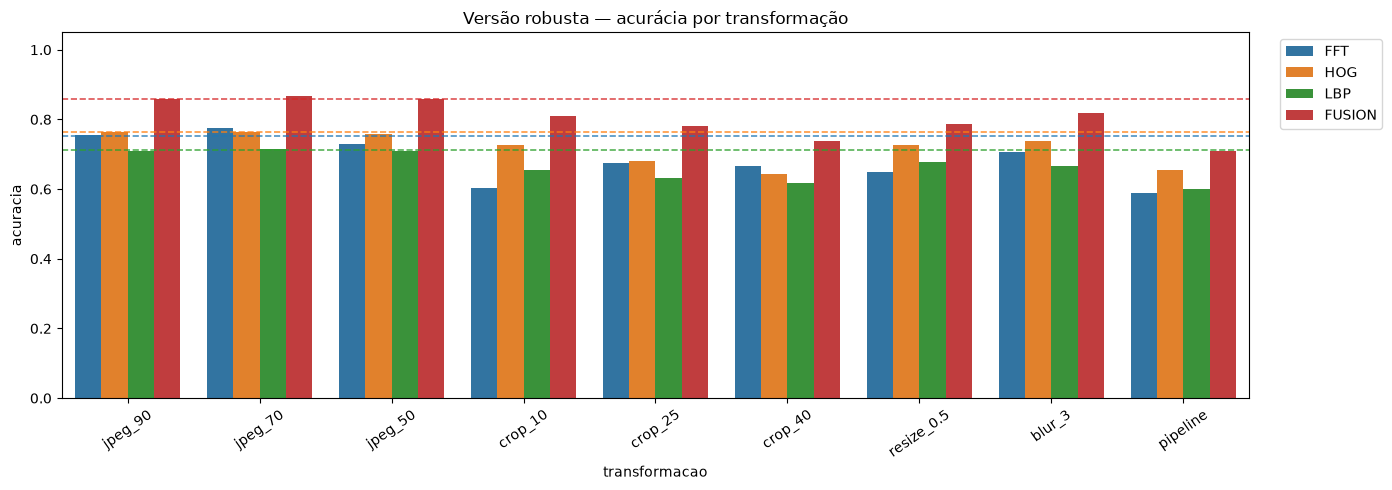

Salvo: /home/konath/Documentos/VC/DeteccaoImagensSinteticas/Cod/results/acuracia_robusto.png


In [18]:
# Barras: acurácia por transformação × feature
ordem_transf = list(TRANSFORMACOES.keys())
ordem_features = [t.upper() for t in tipos_features] + ["FUSION"]
df_plot = df_robustez.copy()
df_plot["transformacao"] = pd.Categorical(df_plot["transformacao"], categories=ordem_transf, ordered=True)
df_plot["feature"] = pd.Categorical(df_plot["feature"], categories=ordem_features, ordered=True)

fig, ax = plt.subplots(figsize=(14, 5))
sns.barplot(data=df_plot, x="transformacao", y="acuracia", hue="feature", ax=ax)
cores = sns.color_palette(n_colors=4)
for i, tipo in enumerate(list(tipos_features) + ["fusion"]):
    ax.axhline(baseline_results[tipo]["acuracia"], color=cores[i], linestyle="--", linewidth=1.2, alpha=0.8)
ax.set_ylim(0, 1.05)
ax.set_title("Versão robusta — acurácia por transformação")
ax.tick_params(axis="x", rotation=35)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
caminho_fig = RESULTS_DIR / "acuracia_robusto.png"
fig.savefig(caminho_fig, dpi=150, bbox_inches="tight")
plt.show()
print("Salvo:", caminho_fig)


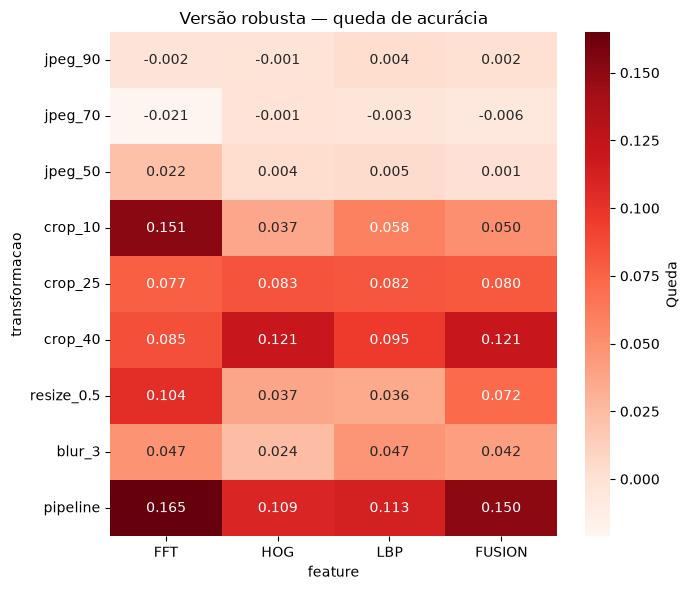

Salvo: /home/konath/Documentos/VC/DeteccaoImagensSinteticas/Cod/results/heatmap_robusto.png

Acurácia FUSION no teste original: 0.8597


In [19]:
# Heatmap da queda (teste original − teste transformado)
pivot_queda = df_robustez.pivot(index="transformacao", columns="feature", values="queda").reindex(
    index=ordem_transf, columns=ordem_features
)
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(pivot_queda, annot=True, fmt=".3f", cmap="Reds", ax=ax, cbar_kws={"label": "Queda"})
ax.set_title("Versão robusta — queda de acurácia")
plt.tight_layout()
caminho_heat = RESULTS_DIR / "heatmap_robusto.png"
fig.savefig(caminho_heat, dpi=150, bbox_inches="tight")
plt.show()
print("Salvo:", caminho_heat)
print("\nAcurácia FUSION no teste original:", f"{baseline_results['fusion']['acuracia']:.4f}")
